In [1]:
import importlib
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, log_loss
import matplotlib.pyplot as plt
import os
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from tqdm import tqdm
import gc

In [2]:
class Config:
    DATA_DIR= '../data'
    VER= 'v13'
    OUTPUT_DIR='../outputs'

In [3]:
train = pd.read_csv(f'{Config.DATA_DIR}/Train.csv')
test = pd.read_csv(f'{Config.DATA_DIR}/Test.csv')
ss = pd.read_csv(f'{Config.DATA_DIR}/SampleSubmission.csv')

target_col = 'income_above_limit'
train[target_col] = train[target_col].map({'Below limit': 0, 'Above limit': 1})

fts = [c for c in train.columns if c not in ['ID', target_col]]
cat_cols = train[fts].select_dtypes('object').columns.tolist()
cat_cols = list(set(cat_cols + ['industry_code', 'occupation_code', 'employment_stat', 'total_employed', 'vet_benefit',
                                'mig_year'
                                ]))

num_cols = [c for c in fts if c not in cat_cols]

null_fts = []
for f in fts:
    train[f'{f}_isnull'] = train[f].isnull().astype(int)
    test[f'{f}_isnull'] = test[f].isnull().astype(int)
    null_fts.append(f'{f}_isnull')


In [4]:
cat_cols = train[fts].select_dtypes('object').columns.tolist()
cat_cols = list(set(cat_cols + ['industry_code', 'occupation_code', 'employment_stat', 'total_employed', 'vet_benefit',
                                'mig_year'
                                ]))

In [5]:
n = 10

df = train.append(test)
for f in fts:
    train[f'{f}_freq'] = train[f].map(df[f].value_counts(normalize=True))
    test[f'{f}_freq'] = test[f].map(df[f].value_counts(normalize=True))
    


agg_num_cols = [
 'losses',
 'gains',
 ]


for c in tqdm(['education', 'industry_code', 'household_stat']):
    grp = df.groupby(c)[agg_num_cols].agg(['mean', 'std'])
    grp.columns = [f'{c}_{col[0]}_{col[1]}' for col in grp.columns]
    train = train.merge(grp, on=c, how='left')
    test = test.merge(grp, on=c, how='left')

100%|██████████| 3/3 [00:03<00:00,  1.06s/it]


In [6]:
def get_features(df):
    
    df[f'education_nunq_occupation_code_main'] = df.groupby('education')['occupation_code_main'].transform('nunique')
    df[f'occupation_code_main_nunq_education'] = df.groupby('occupation_code_main')['education'].transform('nunique')
    
    return df


train = get_features(train)
test = get_features(test)

C:\Users\devni\AppData\Local\Temp\ipykernel_25536\3348512372.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'education_nunq_occupation_code_main'] = df.groupby('education')['occupation_code_main'].transform('nunique')
C:\Users\devni\AppData\Local\Temp\ipykernel_25536\3348512372.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'occupation_code_main_nunq_education'] = df.groupby('occupation_code_main')['education'].transform('nunique')


In [7]:
df = pd.concat([train, test]).reset_index(drop=True)


grp = df.groupby(['occupation_code', 'industry_code'])['gains'].mean().unstack('industry_code')
grp.columns = [f'occ_ind_{c}' for c in grp.columns]
df = df.merge(grp, on='occupation_code', how='left')

grp = df.groupby(['occupation_code', 'industry_code'])['losses'].mean().unstack('industry_code')
grp.columns = [f'losses_mean_occ_ind_{c}' for c in grp.columns]
df = df.merge(grp, on='occupation_code', how='left')


grp = df.groupby([ 'employment_commitment', 'household_stat'])['gains'].mean().unstack('household_stat')
grp.columns = [f'employment_commitment_household_stat_{c}' for c in grp.columns]
df = df.merge(grp, on='employment_commitment', how='left')

train, test = df.iloc[:len(train)], df.iloc[len(train):]

In [8]:
fts = [c for c in train.columns if c not in ['ID', target_col, 'cat_magic']]
tmp = train[fts].isnull().mean().sort_values(ascending=False)

cat_cols = train[fts].select_dtypes('object').columns.tolist()
print(f'Total features are: {len(fts)}')

Total features are: 279


In [9]:
class RankEncoding:
    
    def __init__(self, cat_cols):
        self.cat_cols = cat_cols
        self.mapper = {}
        for c in self.cat_cols:
            self.mapper[c] = {}
    def fit(self, train, target):
        train_tmp = train.copy()
        train_tmp['target'] = target
        for c in self.cat_cols:
            if c not in train_tmp.columns:
                continue
            
            self.mapper[c] = train_tmp[[c, 'target']].groupby(c)['target'].mean().rank()
        
    def fit_transform(self, train, target):
        train_tmp = train.copy()
        train_tmp['target'] = target
        for c in self.cat_cols:
            if c not in train_tmp.columns:
                continue
            
            self.mapper[c] = train_tmp[[c, 'target']].groupby(c)['target'].mean().rank()
            train[c + '_rank_encoded'] = train[c].map(self.mapper[c])
        return train
        
    def transform(self, test):
        for c in self.cat_cols:
            if c not in test.columns:
                continue
            
            test[c + '_rank_encoded'] = test[c].map(self.mapper[c])
        return test

class EnsembleModel:
  
    def __init__(self, fts, cat_cols, group_col=None, n_splits=15, rank_encoding=False, model='lightgbm'):
        """
        The function takes in a dataframe, a list of categorical columns, a group column, and a number
        of splits
        
        :param fts: the features you want to use to train the model
        :param cat_cols: list of categorical columns
        :param group_col: The column that you want to group by
        :param n_splits: number of splits to use for cross-validation, defaults to 15 (optional)
        """
      
        self.cat_cols = cat_cols
        self.cat_cols_mapper = {}
        self.fts = fts
        self.group_col = group_col
        self.n_splits=n_splits
        self.fi_df_permutation = pd.DataFrame()
        self.fi_df = pd.DataFrame()
        self.rank_encoding=rank_encoding
        self.model = model
        if self.rank_encoding:
            self.rank_encoders=[]

    def comp_metric(self, y_true, y_pred):
        """
        The function takes in two arguments, y_true and y_pred, and returns the log loss between them
        
        :param y_true: the true labels
        :param y_pred: The predicted values
        :return: The log loss of the predictions.
        """
        return log_loss(y_true, y_pred)

    def preprocess(self, df, is_train=True):
        """
        It takes in a dataframe and a boolean value, and returns a dataframe with categorical columns
        mapped to integers
        
        :param df: The dataframe to be preprocessed
        :param is_train: This is a boolean parameter that tells the preprocessor whether it's being
        called on the training data or the test data, defaults to True (optional)
        :return: The dataframe with the categorical columns mapped to integers.
        """
           
        if self.cat_cols is None:
            self.cat_cols = []

        #### To do preprocessing on categorical columns
        for c in self.cat_cols:
            if c in df.columns:
                if is_train == True:
                    #### Create a dictionary to map each unique string value to an integer
                    self.cat_cols_mapper[c] = pd.Series(index=df[c].dropna().unique(), data=np.arange(df[c].nunique())).to_dict()

                df[c] = df[c].map(self.cat_cols_mapper[c])

        return df
    
    
    def permutation_importance(self, model, X, y, ):
        np.random.seed(123)
        scores = {}
        
        for  f in tqdm(self.fts):
            X_tmp = X.copy()
            X_tmp[f] = np.random.permutation(X_tmp[f].values)
            preds = model.predict_proba(X_tmp)[:, 1]
            scores[f] = self.comp_metric(y, preds)
        scores = pd.Series(scores)
        scores.name = 'imp'
        scores.index.name = 'ft'
        scores_df = scores.reset_index()
        return scores_df
    
    def add_random_nans(self, X, y, nan_frac=0.1, n_repeats=3):
        
        res = [X.copy()]
        y_orig = y.copy()
        
        for i in tqdm(range(n_repeats)):
            X_temp = X.copy()
            for f in X.columns:
                random_indices = np.random.choice(X.index, size=int(X.shape[0]*nan_frac), replace=False)
                X_temp.loc[random_indices, f] = np.nan
            res.append(X_temp)
            y = y.append(y_orig)
        
            
        X_new = pd.concat(res, axis=0).reset_index(drop=True)
        print(X_new.shape, y.shape, y_orig.shape, )
        return X_new, y
        

    def fit(self, X, y, params=None, random_seed=123):
        """
        It takes in the training data, the target variable, and the parameters for the LGBM model. It
        then splits the data into folds, and trains the model on each fold. It then prints the
        feature importances, the out of fold predictions, and the mean and standard deviation of the
        validation scores
        
        :param X: The training data
        :param y: The target variable
        :param lgb_params: This is the parameters for the LGBMClassifier. If you don't pass any
        parameters, the default ones will be used
        """

        ### Defining fts so that the order of features does not change during prediction time
        X = X.copy()
        X = self.preprocess(X, is_train=True)
        
        print(f'Total features being used are: {len(self.fts)}')
        print("\n")
        self.models = {}

        N_FOLDS = self.n_splits
        if self.group_col is not None:
            folds = StratifiedGroupKFold(N_FOLDS)
            splits = folds.split(X, y, X[self.group_col])
            
        else:
            folds = StratifiedKFold(self.n_splits, shuffle=True, random_state=random_seed)
            splits = folds.split(X, y)
            
        oofs = np.zeros(len(X))

        val_scores = []
        val_idxs = []
        

        for fold_, (trn_idx, val_idx) in enumerate(splits):
        
            val_idxs.append(val_idx)
            X_trn, y_trn = X[self.fts].iloc[trn_idx], y.iloc[trn_idx]
            X_val, y_val = X[self.fts].iloc[val_idx], y.iloc[val_idx]
            

                
            
            if self.rank_encoding:
                re = RankEncoding(cat_cols=self.cat_cols)
                X_trn = re.fit_transform(X_trn, y_trn)
                X_val = re.transform(X_val)
                self.rank_encoders.append(re)
            
            # X_trn, y_trn = self.add_random_nans(X_trn, y_trn)
            
            del trn_idx
            _  = gc.collect()

            if self.model == 'catboost':

                if params is None:
                    params = {
                        'n_estimators': 3500,
                        'learning_rate': 0.05,
                        'rsm': 0.3,
                        'max_depth': 4,
                        'reg_lambda': 0.1,
                    }

                clf = CatBoostClassifier(**params)
                            
                clf.fit(X_trn, y_trn, eval_set=[(X_val, y_val)], verbose=50, early_stopping_rounds=200)
                
            elif self.model == 'lightgbm':
                if params is None:
                    params = {
                        'n_estimators': 4000,
                        'learning_rate': 0.03,
                        'colsample_bytree': 0.26,
                        'num_leaves': 55,
                        'max_depth': -1,
                        'max_bin': 223,
                        'min_child_samples': 50,
                        'reg_lambda': 0.05,
                        'reg_alpha': 0.5,
  
                    }

                clf = LGBMClassifier(**params)
                            
                callbacks = [lgb.early_stopping(500, verbose=0), lgb.log_evaluation(period=100, show_stdv=True)]

                clf.fit(X_trn, y_trn, eval_set=[(X_trn, y_trn), (X_val, y_val)], callbacks=callbacks)
                
            else:
                raise ValueError(f'Model {self.model} not supported')
                

            vp = clf.predict_proba(X_val)[:, 1]
            val_score = self.comp_metric(y_val, vp)
            print(f'Fold {fold_} val score: {val_score}')
            oofs[val_idx] = vp

            val_scores.append(val_score)
            self.models[f'lgbm_{fold_}'] = clf

            new_fts = list(X_trn.columns)
            self.new_fts = new_fts
            
            self.fi_df = self.fi_df.append(pd.DataFrame({'ft': new_fts, 'imp': clf.feature_importances_}))
            # perm_fi_df = self.permutation_importance(clf, X_val.iloc[:3000], y_val.iloc[:3000])
            # self.fi_df_permutation = self.fi_df_permutation.append(perm_fi_df)

            del X_trn, y_trn, X_val, y_val, val_idx

            _ = gc.collect()
            

        self.oofs = oofs
        self.fi = self.fi_df.groupby('ft')['imp'].mean().sort_values(ascending=False)
        # self.fi_perm = self.fi_df_permutation.groupby('ft')['imp'].mean().sort_values(ascending=False)
        
        print(f'\nTop 20 feature importances\n')
        print(self.fi[:20])

        oof_score = self.comp_metric(y, oofs)
        val_scores_std = np.round(np.std(val_scores), 4)
        val_scores_mean = np.round(np.mean(val_scores), 4)
        
        
        print(f'\n---Relogging each fold scores---\n')

        for i, val_idx in enumerate(val_idxs):
            score = self.comp_metric(y.iloc[val_idx], oofs[val_idx])
            print(f'Fold {i} val score: {score}')

        print(f'\nMean of val scores is {val_scores_mean} with a std of {val_scores_std}')
        print(f'OOF score: {oof_score}')


    def predict(self, X):
        """
        We first preprocess the data, then we replace the features not found in the test data with
        np.nan, then we make predictions using each model, and finally we average the predictions of all
        models to get the final predictions.
        
        :param X: The training data
        :return: The average of the predictions of all models
        """
        X = X.copy()
        #### Preprocess testing data before predictions
        X = self.preprocess(X, is_train=False)

        ### Replacing features not found in test with np.nan
        not_found_fts = np.setdiff1d(self.fts, X.columns)     
        for f in not_found_fts:
            X[f] = np.nan
            
        preds_lst = []
        for i, model_name in tqdm(enumerate(self.models.keys())):
            clf = self.models[model_name]
            X_tmp = X.copy()
            
            if self.rank_encoding:
                re = self.rank_encoders[i]
                X_tmp = re.transform(X_tmp)
            
            preds_lst.append(clf.predict_proba(X_tmp[self.new_fts])[:, 1])

        #### Final Predictions is avg of the predictions of all models
        preds = np.array(preds_lst).mean(axis=0)

        return preds


In [10]:
fts = [c for c in train.columns if c not in ['ID', target_col, 'cat_magic']]
tmp = train[fts].isnull().mean().sort_values(ascending=False)

cat_cols = train[fts].select_dtypes('object').columns.tolist()
print(f'Total features are: {len(fts)}')

Total features are: 279


In [11]:
cat_cols = train[fts].select_dtypes('object').columns.tolist()
cat_cols = list(set(cat_cols + ['industry_code', 'occupation_code', 'employment_stat', 'total_employed', 'vet_benefit',
                                'mig_year'
                                ]))

In [12]:
all_oofs = []
all_models = []
for random_seed in [17, 14, 21, 28, 56]:
    clf_lgb = EnsembleModel(fts=fts, cat_cols=cat_cols, n_splits=5, rank_encoding=False, model='lightgbm')
    clf_lgb.fit(train, train[target_col], random_seed=random_seed)
    all_models.append(clf_lgb)
    all_oofs.append(clf_lgb.oofs)

Total features being used are: 279


[100]	training's binary_logloss: 0.111772	valid_1's binary_logloss: 0.118028
[200]	training's binary_logloss: 0.100403	valid_1's binary_logloss: 0.111516
[300]	training's binary_logloss: 0.0941611	valid_1's binary_logloss: 0.10981
[400]	training's binary_logloss: 0.0896213	valid_1's binary_logloss: 0.109216
[500]	training's binary_logloss: 0.0857502	valid_1's binary_logloss: 0.108849
[600]	training's binary_logloss: 0.0825339	valid_1's binary_logloss: 0.108674
[700]	training's binary_logloss: 0.079596	valid_1's binary_logloss: 0.108591
[800]	training's binary_logloss: 0.0768224	valid_1's binary_logloss: 0.108523
[900]	training's binary_logloss: 0.0742265	valid_1's binary_logloss: 0.108576
[1000]	training's binary_logloss: 0.0717565	valid_1's binary_logloss: 0.108657
[1100]	training's binary_logloss: 0.0695011	valid_1's binary_logloss: 0.108804
[1200]	training's binary_logloss: 0.0672818	valid_1's binary_logloss: 0.108935
Fold 0 val score: 0.10848909

In [13]:
mean_oofs = np.mean(all_oofs, axis=0)
log_loss(train[target_col], mean_oofs)

0.10583539175402522

In [14]:
final_oofs = mean_oofs

In [15]:
log_loss(train[target_col], final_oofs)

0.10583539175402522

In [16]:

train['preds'] = final_oofs

C:\Users\devni\AppData\Local\Temp\ipykernel_25536\3036883782.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['preds'] = final_oofs


In [17]:
def plot_f1_against_thresholds(y_true, y_pred):
    global threshold
    
    scores = {}
    thresholds = np.arange(0, 1.01, 0.005)
    
    for threshold in thresholds:
        scores[threshold] = f1_score(y_true, y_pred > threshold)
        
    print(np.max(pd.Series(scores).values))
    print(thresholds[np.argmax(pd.Series(scores))])
        
    threshold = thresholds[np.argmax(pd.Series(scores))]
    return plt.plot(list(scores.keys()), list(scores.values()))

0.6464638754246022
0.31


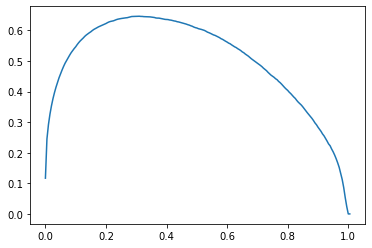

In [18]:
plot_f1_against_thresholds(train[target_col], train['preds'])

In [19]:
# test['preds'] = (clf_lgb.predict(test) * 0.5 +clf_lgb_re.predict(test)*0.5)*0.5+ (clf_cb.predict(test) * 0.5 + clf_cb_re.predict(test)*0.5)*0.5

In [20]:
test_preds = []

for model in all_models:
    test_preds.append(model.predict(test))
    

5it [00:06,  1.32s/it]
5it [00:06,  1.24s/it]
5it [00:06,  1.24s/it]
5it [00:06,  1.21s/it]
5it [00:06,  1.24s/it]


In [21]:
pd.Series(test_preds[0]).describe()

count    89786.000000
mean         0.060590
std          0.163830
min          0.000002
25%          0.000014
50%          0.002973
75%          0.025180
max          0.999776
dtype: float64

In [22]:
pd.Series(all_models[0].oofs).describe()

count    2.094990e+05
mean     6.077073e-02
std      1.655934e-01
min      6.307870e-07
25%      1.382117e-05
50%      2.851089e-03
75%      2.470268e-02
max      9.998954e-01
dtype: float64

In [23]:
test_preds_avgd = np.mean(test_preds, axis=0)

In [24]:
test_preds_avgd.max()

0.9997771495075647

In [25]:
test['preds'] = test_preds_avgd

C:\Users\devni\AppData\Local\Temp\ipykernel_25536\3389789178.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['preds'] = test_preds_avgd


In [26]:
train['preds'].describe()

count    209499.000000
mean          0.060817
std           0.164592
min           0.000001
25%           0.000015
50%           0.003066
75%           0.025518
max           0.999904
Name: preds, dtype: float64

In [27]:
test['preds'].describe()

count    89786.000000
mean         0.060632
std          0.163421
min          0.000003
25%          0.000015
50%          0.003068
75%          0.025625
max          0.999777
Name: preds, dtype: float64

In [28]:
f1_score(train[target_col], train['preds'] > 0.32)

0.6458220607559714

In [29]:
ss['income_above_limit'] = (test['preds'].values > 0.32)*1
ss['income_above_limit'].value_counts(normalize=True)

0    0.938743
1    0.061257
Name: income_above_limit, dtype: float64

In [30]:
ss.to_csv(os.path.join(Config.OUTPUT_DIR, f'submission_{Config.VER}.csv'), index=False)

In [31]:
train[['ID', 'preds']].to_csv(os.path.join(Config.OUTPUT_DIR, f'train_preds_{Config.VER}.csv'), index=False)
test[['ID', 'preds']].to_csv(os.path.join(Config.OUTPUT_DIR, f'test_preds_{Config.VER}.csv'), index=False)

In [32]:
Config.VER

'v13'